# Bank Customer Churn Prediction using Neural Network

**Aim:** Given a bank customer, build a neural-network classifier to predict whether the customer will leave (churn) or stay.

**Target column:** `Exited`
- `0` = Customer will stay
- `1` = Customer will leave

**Dataset:** Kaggle Bank Customer Churn Modelling (`Churn_Modelling.csv`).

Keep `Churn_Modelling.csv` in the same folder as this notebook.

## 1. Import required libraries

In [4]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## 2. Read the dataset

In [5]:
df = pd.read_csv('Churn_Modelling.csv')

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Explore the dataset

In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


Missing values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
\nTarget distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


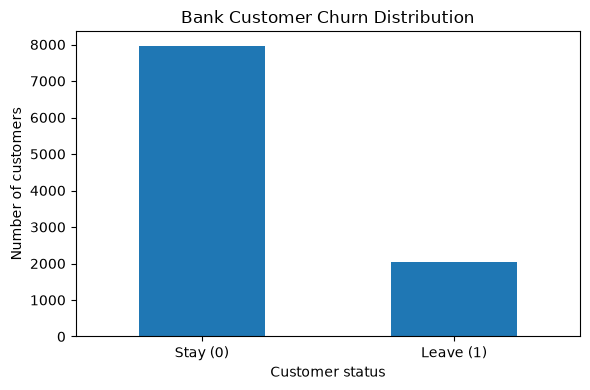

In [7]:
print("Missing values:")
print(df.isnull().sum())

print("\\nTarget distribution:")
print(df['Exited'].value_counts())

plt.figure(figsize=(6, 4))
df['Exited'].value_counts().sort_index().plot(kind='bar')
plt.xticks([0, 1], ['Stay (0)', 'Leave (1)'], rotation=0)
plt.xlabel('Customer status')
plt.ylabel('Number of customers')
plt.title('Bank Customer Churn Distribution')
plt.tight_layout()
plt.show()


## 4. Data preprocessing and encoding

In [8]:
# Convert categorical columns into numerical dummy variables.
df = pd.concat(
    [df, pd.get_dummies(df['Geography'], prefix='Geo', dtype=int)],
    axis=1
)

df = pd.concat(
    [df, pd.get_dummies(df['Gender'], prefix='Gender', drop_first=True, dtype=int)],
    axis=1
)

# Remove identifier and original categorical columns.
df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname', 'Geography', 'Gender'],
    inplace=True,
    errors='ignore'
)

df.head()


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geo_France,Geo_Germany,Geo_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,1,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,0,1,0


In [9]:
print("Columns after preprocessing:")
print(df.columns.tolist())

print("\\nMissing values after preprocessing:")
print(df.isnull().sum())


Columns after preprocessing:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geo_France', 'Geo_Germany', 'Geo_Spain', 'Gender_Male']
\nMissing values after preprocessing:
CreditScore        0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
Geo_France         0
Geo_Germany        0
Geo_Spain          0
Gender_Male        0
dtype: int64


## 5. Distinguish features and target

In [10]:
# Exited is the target:
# 0 = Customer stays, 1 = Customer leaves.

y = df['Exited'].values
x = df.drop(columns=['Exited']).values

print("Feature shape:", x.shape)
print("Target shape:", y.shape)
print("Number of input features:", x.shape[1])


Feature shape: (10000, 12)
Target shape: (10000,)
Number of input features: 12


## 6. Divide the dataset into training and testing sets

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.25,
    random_state=20,
    stratify=y
)

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (7500, 12)
Testing features: (2500, 12)
Training target: (7500,)
Testing target: (2500,)


## 7. Normalize the training and testing data

In [12]:
std_x = StandardScaler()

# Fit the scaler only on training data to avoid data leakage.
x_train = std_x.fit_transform(x_train)
x_test = std_x.transform(x_test)

print("Normalized training data shape:", x_train.shape)
print("Normalized testing data shape:", x_test.shape)


Normalized training data shape: (7500, 12)
Normalized testing data shape: (2500, 12)


## 8. Build the initial neural network model

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,401 (5.47 KB)

 Trainable params: 1,401 (5.47 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Train the initial model

In [14]:
history = model.fit(
    x_train,
    y_train,
    batch_size=64,
    validation_split=0.1,
    epochs=100,
    verbose=1
)


Epoch 1/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7876 - loss: 0.4930 - val_accuracy: 0.8293 - val_loss: 0.4218
Epoch 2/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8187 - loss: 0.4216 - val_accuracy: 0.8307 - val_loss: 0.3954
Epoch 3/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8273 - loss: 0.4037 - val_accuracy: 0.8440 - val_loss: 0.3817
Epoch 4/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8410 - loss: 0.3875 - val_accuracy: 0.8560 - val_loss: 0.3669
Epoch 5/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8467 - loss: 0.3739 - val_accuracy: 0.8627 - val_loss: 0.3580
Epoch 6/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8521 - loss: 0.3640 - val_accuracy: 0.8693 - val_loss: 0.3512
Epoch 7/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8535 - loss: 0.3573 - val_accuracy: 0.8707 - val_loss: 0.3444
Epoch 8/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8564 - loss: 0.3516 - val_accu

## 10. Evaluate the initial model

In [15]:
initial_probabilities = model.predict(x_test).ravel()
initial_predictions = (initial_probabilities >= 0.5).astype(int)

initial_accuracy = accuracy_score(y_test, initial_predictions)

print("Initial Model Accuracy:", initial_accuracy)
print("\\nClassification Report:")
print(classification_report(
    y_test,
    initial_predictions,
    target_names=['Stay (0)', 'Leave (1)'],
    zero_division=0
))


79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 759us/step
Initial Model Accuracy: 0.86
\nClassification Report:
              precision    recall  f1-score   support

    Stay (0)       0.88      0.96      0.92      1991
   Leave (1)       0.75      0.47      0.58       509

    accuracy                           0.86      2500
   macro avg       0.81      0.71      0.75      2500
weighted avg       0.85      0.86      0.85      2500



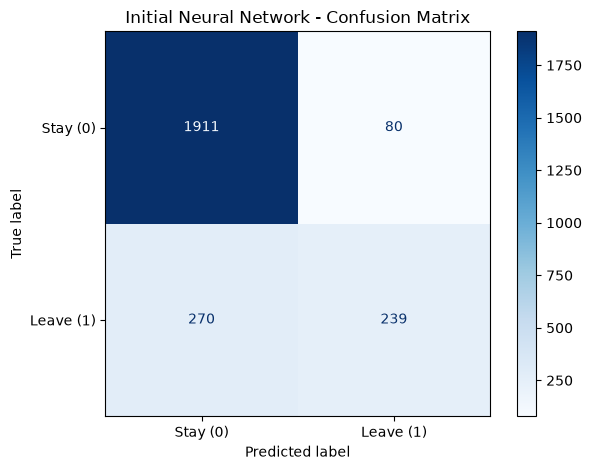

In [16]:
cm = confusion_matrix(y_test, initial_predictions)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stay (0)', 'Leave (1)']
)
display.plot(cmap='Blues')
plt.title('Initial Neural Network - Confusion Matrix')
plt.tight_layout()
plt.show()


## 11. Identify points of improvement

The initial model contains one hidden layer. It can be improved by:

1. Adding another hidden layer so the network can learn more complex patterns.
2. Using `EarlyStopping` to stop training when validation loss no longer improves.
3. Restoring the weights from the best validation-loss epoch to reduce overfitting.

The following model implements these improvements. The same training and test data are used for a fair comparison.

## 12. Build and train the improved neural network

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

improved_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(50, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

improved_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

improved_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 100)            │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,401 (25.00 KB)

 Trainable params: 6,401 (25.00 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    x_train,
    y_train,
    batch_size=64,
    validation_split=0.1,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7984 - loss: 0.4638 - val_accuracy: 0.8213 - val_loss: 0.4084
Epoch 2/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8308 - loss: 0.4006 - val_accuracy: 0.8573 - val_loss: 0.3784
Epoch 3/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8502 - loss: 0.3687 - val_accuracy: 0.8720 - val_loss: 0.3506
Epoch 4/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8587 - loss: 0.3502 - val_accuracy: 0.8693 - val_loss: 0.3409
Epoch 5/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8576 - loss: 0.3425 - val_accuracy: 0.8747 - val_loss: 0.3432
Epoch 6/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8601 - loss: 0.3392 - val_accuracy: 0.8680 - val_loss: 0.3422
Epoch 7/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8627 - loss: 0.3357 - val_accuracy: 0.8720 - val_loss: 0.3401
Epoch 8/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8599 - loss: 0.3330 - val_accu

## 13. Evaluate the improved model

In [19]:
improved_probabilities = improved_model.predict(x_test).ravel()
improved_predictions = (improved_probabilities >= 0.5).astype(int)

improved_accuracy = accuracy_score(y_test, improved_predictions)

print("Improved Model Accuracy:", improved_accuracy)
print("\\nClassification Report:")
print(classification_report(
    y_test,
    improved_predictions,
    target_names=['Stay (0)', 'Leave (1)'],
    zero_division=0
))


79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 855us/step
Improved Model Accuracy: 0.8568
\nClassification Report:
              precision    recall  f1-score   support

    Stay (0)       0.87      0.96      0.91      1991
   Leave (1)       0.75      0.45      0.56       509

    accuracy                           0.86      2500
   macro avg       0.81      0.71      0.74      2500
weighted avg       0.85      0.86      0.84      2500



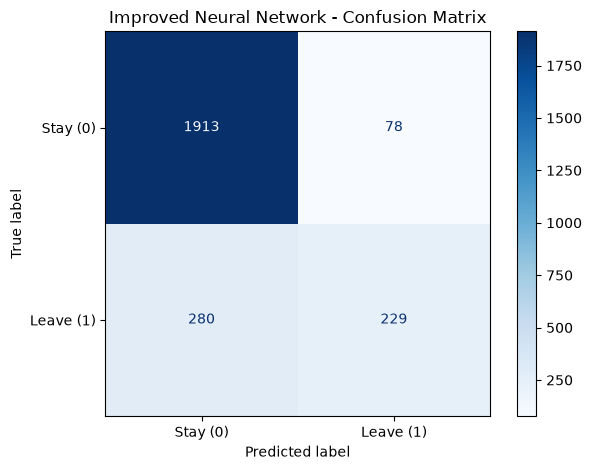

In [20]:
cm_improved = confusion_matrix(y_test, improved_predictions)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_improved,
    display_labels=['Stay (0)', 'Leave (1)']
)
display.plot(cmap='Blues')
plt.title('Improved Neural Network - Confusion Matrix')
plt.tight_layout()
plt.show()


## 14. Compare initial and improved models

In [21]:
comparison = pd.DataFrame({
    'Model': ['Initial Neural Network', 'Improved Neural Network'],
    'Accuracy': [initial_accuracy, improved_accuracy]
})

comparison


,Model,Accuracy
0,Initial Neural Network,0.8600
1,Improved Neural Network,0.8568


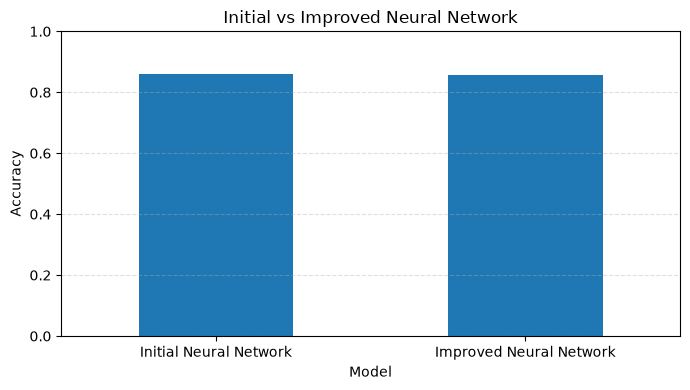

In [22]:
comparison.set_index('Model')['Accuracy'].plot(
    kind='bar',
    figsize=(7, 4),
    ylim=(0, 1),
    rot=0
)
plt.ylabel('Accuracy')
plt.title('Initial vs Improved Neural Network')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## 15. Result and conclusion

A neural-network-based classifier was developed to predict whether a bank customer will stay or leave. The dataset was loaded, categorical features were encoded, features and target were separated, and the data was divided into training and testing sets. The input features were normalized using `StandardScaler`.

An initial neural network and an improved neural network were trained. The improved model uses an additional hidden layer and EarlyStopping. Accuracy scores and confusion matrices were generated to evaluate the models.

**Conclusion:** Compare the measured accuracy and confusion matrices above to determine which model performed better on this test set. The confusion matrix also shows the number of customers correctly and incorrectly classified as staying or leaving.